# CPC-PKL: clean fine-tuning + evaluation run
**Qwen2.5-7B-Instruct · QLoRA · 2×T4 (DDP)**

Before running:
- **Settings → Accelerator:** GPU T4 x2
- **Settings → Internet:** ON
- **Dependencies:** `pip install "transformers==4.51.3" "peft==0.15.2" "trl==0.17.0" "accelerate==1.6.0" "bitsandbytes==0.45.5" "datasets==3.5.0" evaluate rouge_score bert_score`
- **Input:** the dataset containing `final_legal_dataset.json` (set `DATA_PATH` in Cell 1)

Best way to run: **Save Version → Save & Run All (Commit)**. It runs in the background (no idle timeout) and keeps everything in `/kaggle/working` as notebook output.

| Cell | What it does | Time |
|---|---|---|
| 1 | Config, GPU check, clean old outputs | seconds |
| 2 | Stratified 80/10/10 split (seed 42) | seconds |
| 3–4 | Fine-tune on both GPUs | ~2–3 h |
| 5–6 | Generate answers for all 246 test questions (base + fine-tuned), both GPUs | ~40–70 min |
| 7 | All metrics, per-category tables, significance tests, examples | ~5 min |
| 8 | Loss curve figure | seconds |
| 9 | Zip everything for download | ~1 min |

In [1]:
# ===== CELL 1: Config + environment check + clean previous run =====
import os, glob, shutil, torch, transformers, peft, bitsandbytes

DATA_PATH = "/kaggle/input/datasets/atifkhan89/final-legal-dataset/final_legal_dataset.json"
WORK      = "/kaggle/working"
DATA_DIR  = f"{WORK}/data"
MODEL_DIR = f"{WORK}/qwen25-7b-cpc-lora"
PRED_DIR  = f"{WORK}/preds"
EVAL_DIR  = f"{WORK}/eval_clean"

print("Torch", torch.__version__, "| transformers", transformers.__version__,
      "| peft", peft.__version__, "| bitsandbytes", bitsandbytes.__version__)
n = torch.cuda.device_count()
for i in range(n):
    print(f"GPU {i}: {torch.cuda.get_device_name(i)}")
assert n == 2, "Need 2 GPUs: Settings > Accelerator > GPU T4 x2"
assert transformers.__version__ == "4.51.3", "Wrong transformers version: check the dependency manager"

if not os.path.exists(DATA_PATH):
    print("\nDATA_PATH not found. JSON files available:")
    for f in glob.glob("/kaggle/input/**/*.json", recursive=True):
        print("  ", f)
    raise FileNotFoundError("Set DATA_PATH to your final_legal_dataset.json path above")

# Clean run: remove outputs of any previous run (eval_full from the old run is kept)
for d in [DATA_DIR, MODEL_DIR, PRED_DIR, EVAL_DIR]:
    shutil.rmtree(d, ignore_errors=True)
    os.makedirs(d, exist_ok=True)
print("\nReady. Dataset:", DATA_PATH)

Torch 2.11.0+cu128 | transformers 4.51.3 | peft 0.15.2 | bitsandbytes 0.45.5
GPU 0: Tesla T4
GPU 1: Tesla T4

Ready. Dataset: /kaggle/input/datasets/atifkhan89/final-legal-dataset/final_legal_dataset.json


In [2]:
# ===== CELL 2: Validate + stratified 80/10/10 split =====
import json, random
from collections import Counter

SEED = 42
with open(DATA_PATH, encoding="utf-8") as f:
    data = json.load(f)
if isinstance(data, dict):
    data = next(v for v in data.values() if isinstance(v, list))

bad = [i for i, x in enumerate(data)
       if not {"instruction", "output", "type"} <= set(x) or not x["instruction"].strip() or not x["output"].strip()]
print(f"Total examples: {len(data)} | Invalid rows: {len(bad)}")
assert not bad, f"Invalid rows: {bad[:10]}"
print("Categories:", dict(Counter(x["type"] for x in data)))

random.seed(SEED)
by_cat = {}
for i, x in enumerate(data):
    x["id"] = i
    by_cat.setdefault(x["type"], []).append(x)

train, val, test = [], [], []
for cat, items in by_cat.items():
    random.shuffle(items)
    k = round(len(items) * 0.10)
    test += items[:k]; val += items[k:2 * k]; train += items[2 * k:]
for s in (train, val, test):
    random.shuffle(s)

def save(rows, name):
    with open(f"{DATA_DIR}/{name}.jsonl", "w", encoding="utf-8") as f:
        for r in rows:
            f.write(json.dumps({"id": r["id"], "question": r["instruction"].strip(),
                                "answer": r["output"].strip(), "category": r["type"]},
                               ensure_ascii=False) + "\n")
save(train, "train"); save(val, "val"); save(test, "test")

print(f"\ntrain {len(train)} | val {len(val)} | test {len(test)}")
print(f"{'Category':<14}{'train':>7}{'val':>6}{'test':>6}")
for cat in by_cat:
    print(f"{cat:<14}{sum(r['type']==cat for r in train):>7}{sum(r['type']==cat for r in val):>6}{sum(r['type']==cat for r in test):>6}")

Total examples: 2467 | Invalid rows: 0
Categories: {'DEFINITIONAL': 996, 'COMPARATIVE': 294, 'PROCEDURAL': 553, 'SCENARIO': 381, 'CONSEQUENCE': 243}

train 1975 | val 246 | test 246
Category        train   val  test
DEFINITIONAL      796   100   100
COMPARATIVE       236    29    29
PROCEDURAL        443    55    55
SCENARIO          305    38    38
CONSEQUENCE       195    24    24


In [3]:
%%writefile /kaggle/working/train.py
# ===== CELL 3: Training script (QLoRA, DDP on 2 GPUs) =====
import os, json, torch
from datasets import load_dataset
from transformers import (AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig,
                          TrainingArguments, Trainer, DataCollatorForSeq2Seq)
from peft import LoraConfig, get_peft_model

MODEL_ID = "Qwen/Qwen2.5-7B-Instruct"
DATA_DIR = "/kaggle/working/data"
OUT_DIR  = "/kaggle/working/qwen25-7b-cpc-lora"
MAX_LEN  = 2048
SYSTEM   = "You are an expert Pakistani legal assistant specialising in the Code of Civil Procedure (CPC) 1908."

local_rank = int(os.environ.get("LOCAL_RANK", 0))
torch.cuda.set_device(local_rank)
print(f"[rank {local_rank}] running on cuda:{local_rank} -> {torch.cuda.get_device_name(local_rank)}")

args = TrainingArguments(
    output_dir=OUT_DIR,
    num_train_epochs=3,
    per_device_train_batch_size=1,
    per_device_eval_batch_size=1,
    gradient_accumulation_steps=8,          # effective batch = 1 x 8 x 2 GPUs = 16
    learning_rate=2e-4,
    lr_scheduler_type="cosine",
    warmup_ratio=0.03,
    max_grad_norm=0.3,
    optim="paged_adamw_8bit",
    fp16=True,                              # T4 has no bf16
    gradient_checkpointing=True,
    gradient_checkpointing_kwargs={"use_reentrant": False},
    logging_steps=5,
    eval_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=2,
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    greater_is_better=False,
    ddp_find_unused_parameters=False,
    report_to="none",
    label_names=["labels"],                 # needed so Trainer computes eval_loss for the PEFT model
    seed=42,
)

tok = AutoTokenizer.from_pretrained(MODEL_ID)
if tok.pad_token is None:
    tok.pad_token = tok.eos_token
tok.padding_side = "right"

def encode(ex):  # loss only on the answer tokens
    prompt = tok.apply_chat_template(
        [{"role": "system", "content": SYSTEM}, {"role": "user", "content": ex["question"]}],
        tokenize=False, add_generation_prompt=True)
    p_ids = tok(prompt, add_special_tokens=False)["input_ids"]
    a_ids = tok(ex["answer"] + tok.eos_token, add_special_tokens=False)["input_ids"]
    ids    = (p_ids + a_ids)[:MAX_LEN]
    labels = ([-100] * len(p_ids) + a_ids)[:MAX_LEN]
    return {"input_ids": ids, "attention_mask": [1] * len(ids), "labels": labels}

with args.main_process_first(desc="tokenize"):
    ds = load_dataset("json", data_files={"train": f"{DATA_DIR}/train.jsonl",
                                          "validation": f"{DATA_DIR}/val.jsonl"})
    ds = ds.map(encode, remove_columns=ds["train"].column_names)

bnb = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4",
                         bnb_4bit_use_double_quant=True, bnb_4bit_compute_dtype=torch.float16)
with args.main_process_first(desc="load model"):
    model = AutoModelForCausalLM.from_pretrained(
        MODEL_ID, quantization_config=bnb, torch_dtype=torch.float16,
        device_map={"": local_rank}, attn_implementation="sdpa")

model.config.use_cache = False
model.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant": False})
model.enable_input_require_grads()
model = get_peft_model(model, LoraConfig(
    r=16, lora_alpha=32, lora_dropout=0.05, bias="none", task_type="CAUSAL_LM",
    target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"]))
if local_rank == 0:
    model.print_trainable_parameters()

trainer = Trainer(
    model=model, args=args,
    train_dataset=ds["train"], eval_dataset=ds["validation"],
    data_collator=DataCollatorForSeq2Seq(tok, padding=True, label_pad_token_id=-100, pad_to_multiple_of=8),
)
trainer.train()

if trainer.is_world_process_zero():
    trainer.save_model(f"{OUT_DIR}/final")
    tok.save_pretrained(f"{OUT_DIR}/final")
    with open(f"{OUT_DIR}/log_history.json", "w") as f:
        json.dump(trainer.state.log_history, f, indent=2)
    print("DONE. Best checkpoint:", trainer.state.best_model_checkpoint)

Overwriting /kaggle/working/train.py


In [4]:
# ===== CELL 4: Train on both GPUs =====
!cd /kaggle/working && PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True TOKENIZERS_PARALLELISM=false \
  torchrun --nproc_per_node=2 train.py 2>&1 | tee train_log.txt
import os
assert os.path.exists(f"{MODEL_DIR}/final/adapter_model.safetensors"), "Training did not finish: check train_log.txt"
print("Adapter saved:", os.listdir(f"{MODEL_DIR}/final"))

W1020 17:21:41.347000 508 torch/distributed/run.py:851] 
W1020 17:21:41.347000 508 torch/distributed/run.py:851] *****************************************
W1020 17:21:41.347000 508 torch/distributed/run.py:851] Setting OMP_NUM_THREADS environment variable for each process to be 1 in default, to avoid your system being overloaded, please further tune the variable for optimal performance in your application as needed. 
W1020 17:21:41.347000 508 torch/distributed/run.py:851] *****************************************
[rank 1] running on cuda:1 -> Tesla T4
[rank 0] running on cuda:0 -> Tesla T4
Generating train split: 1975 examples [00:00, 49695.55 examples/s]
Generating validation split: 246 examples [00:00, 57021.21 examples/s]
Map: 100%|██████████| 246/246 [00:00<00:00, 504.92 examples/s]
/usr/local/lib/python3.13/dist-packages/torch/distributed/c10d_logger.py:83: UserWarning: barrier(): using the device under current context. You can specify `device_id` in `init_process_group` to mute t

In [5]:
%%writefile /kaggle/working/generate.py
# ===== CELL 5: Generation script (each GPU answers half of the test set) =====
import os, sys, json, torch
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig
from peft import PeftModel

MODE     = sys.argv[1]                       # "base" or "ft"
MODEL_ID = "Qwen/Qwen2.5-7B-Instruct"
ADAPTER  = "/kaggle/working/qwen25-7b-cpc-lora/final"
TEST     = "/kaggle/working/data/test.jsonl"
PRED_DIR = "/kaggle/working/preds"
SYSTEM   = "You are an expert Pakistani legal assistant specialising in the Code of Civil Procedure (CPC) 1908."
BATCH, MAX_NEW = 16, 1024

rank  = int(os.environ.get("LOCAL_RANK", 0))
world = int(os.environ.get("WORLD_SIZE", 1))
torch.cuda.set_device(rank); torch.manual_seed(42)

rows = [json.loads(l) for l in open(TEST, encoding="utf-8")][rank::world]
out_path = f"{PRED_DIR}/{MODE}_rank{rank}.jsonl"
done = set()
if os.path.exists(out_path):                 # resume if interrupted
    done = {json.loads(l)["id"] for l in open(out_path, encoding="utf-8")}
rows = sorted([r for r in rows if r["id"] not in done], key=lambda r: len(r["question"]))
print(f"[{MODE} rank {rank}] {len(rows)} questions to answer ({len(done)} already done)", flush=True)

tok = AutoTokenizer.from_pretrained(MODEL_ID)
tok.padding_side = "left"
if tok.pad_token is None:
    tok.pad_token = tok.eos_token

bnb = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4",
                         bnb_4bit_use_double_quant=True, bnb_4bit_compute_dtype=torch.float16)
model = AutoModelForCausalLM.from_pretrained(MODEL_ID, quantization_config=bnb, torch_dtype=torch.float16,
                                             device_map={"": rank}, attn_implementation="sdpa")
if MODE == "ft":
    model = PeftModel.from_pretrained(model, ADAPTER)
model.eval()

def prompt(q):
    return tok.apply_chat_template([{"role": "system", "content": SYSTEM},
                                    {"role": "user", "content": q}],
                                   tokenize=False, add_generation_prompt=True)

with open(out_path, "a", encoding="utf-8") as out:
    for i in range(0, len(rows), BATCH):
        b = rows[i:i + BATCH]
        enc = tok([prompt(r["question"]) for r in b], return_tensors="pt",
                  padding=True, add_special_tokens=False).to(rank)
        with torch.no_grad():
            gen = model.generate(**enc, max_new_tokens=MAX_NEW, do_sample=False,
                                 temperature=None, top_p=None, top_k=None,
                                 repetition_penalty=1.05, pad_token_id=tok.pad_token_id)
        new = gen[:, enc["input_ids"].shape[1]:]
        texts = tok.batch_decode(new, skip_special_tokens=True)
        n_tok = (new != tok.pad_token_id).sum(dim=1).tolist()
        for r, t, n in zip(b, texts, n_tok):
            out.write(json.dumps({"id": r["id"], "prediction": t.strip(),
                                  "new_tokens": n, "truncated": n >= MAX_NEW}, ensure_ascii=False) + "\n")
        out.flush()
        print(f"[{MODE} rank {rank}] {min(i + BATCH, len(rows))}/{len(rows)}", flush=True)
print(f"[{MODE} rank {rank}] DONE", flush=True)

Writing /kaggle/working/generate.py


In [6]:
# ===== CELL 6: Generate answers: base model, then fine-tuned (both GPUs each time) =====
!cd /kaggle/working && TOKENIZERS_PARALLELISM=false torchrun --nproc_per_node=2 generate.py base 2>&1 | grep -v "Sliding Window" | tee gen_base_log.txt
!cd /kaggle/working && TOKENIZERS_PARALLELISM=false torchrun --nproc_per_node=2 generate.py ft   2>&1 | grep -v "Sliding Window" | tee gen_ft_log.txt

import glob, json
for m in ["base", "ft"]:
    n = sum(1 for f in glob.glob(f"{PRED_DIR}/{m}_rank*.jsonl") for _ in open(f))
    print(f"{m}: {n} predictions")

W1020 19:34:46.211000 574 torch/distributed/run.py:851] 
W1020 19:34:46.211000 574 torch/distributed/run.py:851] *****************************************
W1020 19:34:46.211000 574 torch/distributed/run.py:851] Setting OMP_NUM_THREADS environment variable for each process to be 1 in default, to avoid your system being overloaded, please further tune the variable for optimal performance in your application as needed. 
W1020 19:34:46.211000 574 torch/distributed/run.py:851] *****************************************
[base rank 0] 123 questions to answer (0 already done)
[base rank 1] 123 questions to answer (0 already done)
Loading checkpoint shards: 100%|██████████| 4/4 [00:18<00:00,  4.58s/it]
[base rank 1] 16/123
[base rank 0] 16/123
[base rank 1] 32/123
[base rank 0] 32/123
[base rank 1] 48/123
[base rank 0] 48/123
[base rank 1] 64/123
[base rank 0] 64/123
[base rank 1] 80/123
[base rank 0] 80/123
[base rank 1] 96/123
[base rank 0] 96/123
[base rank 1] 112/123
[base rank 0] 112/123
[b

In [7]:
# ===== CELL 7: All metrics: overall, per category, significance, examples =====
import json, glob, re, os, numpy as np, pandas as pd
from scipy.stats import wilcoxon
from rouge_score import rouge_scorer
from bert_score import score as bertscore

pd.set_option("display.width", 250); pd.set_option("display.max_columns", 50); pd.set_option("display.max_rows", 200)
load = lambda p: [json.loads(l) for l in open(p, encoding="utf-8")]
MODELS = {"base": "Base Qwen2.5-7B", "ft": "Fine-tuned (QLoRA)"}
CATS = ["DEFINITIONAL", "PROCEDURAL", "SCENARIO", "COMPARATIVE", "CONSEQUENCE"]

import re

# ---------- Provision extraction (CPC sections, orders, rules) ----------
_ROM = {"I": 1, "V": 5, "X": 10, "L": 50, "C": 100}

def _roman(s):
    s = s.upper(); t = 0
    for i, c in enumerate(s):
        v = _ROM[c]
        t += -v if i + 1 < len(s) and _ROM[s[i + 1]] > v else v
    return t

_NUM  = r"\d{1,3}(?!\d)[A-Za-z]?(?:\s*\([^)]{1,6}\))*"
_LIST = rf"{_NUM}(?:\s*(?:,|and|&|to|or|-)\s*{_NUM})*"
SEC_RE = re.compile(rf"\b(?:sections?|ss?\.)\s*({_LIST})", re.I)
ORD_RE = re.compile(rf"\b(?:order|o\.)\s*([IVXLC]+|\d{{1,2}}(?!\d))\b"
                    rf"(?:\s*,?\s*(?:rules?|r\.)\s*({_LIST}))?", re.I)

def _nums(g):
    return [n.upper() for n in re.findall(r"\d{1,3}[A-Za-z]?", re.sub(r"\([^)]*\)", "", g))]

def provisions(text):
    """Set of normalised provisions, e.g. {'S2', 'S144', 'O21R60', 'O7'}."""
    P = set()
    for m in SEC_RE.finditer(text):
        for n in _nums(m.group(1)):
            P.add(f"S{n}")
    for m in ORD_RE.finditer(text):
        g = m.group(1)
        o = int(g) if g.isdigit() else _roman(g)
        if not 1 <= o <= 51:
            continue
        if m.group(2):
            for r in _nums(m.group(2)):
                P.add(f"O{o}R{r}")
        else:
            P.add(f"O{o}")
    return P

# ---------- Pakistani case-citation extraction ----------
_REP = r"SCMR|CLC|MLD|YLR|PLJ|CLD|PCr\.?\s?LJ|PTD|NLR|KLR|MLR|CLJ|SCJ|PLC|GBLR"
_CRT = r"SC|FSC|Lah|Lahore|Kar|Karachi|Pesh|Peshawar|Quetta|Isl|Islamabad|AJK|Bal|L|K|P|Q|B"
CASE_A = re.compile(rf"\b((?:19|20)\d{{2}})\s+({_REP})\s+(\d{{1,4}})\b")                 # 2005 SCMR 668
CASE_B = re.compile(rf"\b(?:PLD|P\.L\.D\.?|P)\s+((?:19|20)\d{{2}})\s+(?:{_CRT})\.?\s+(\d{{1,4}})\b")  # PLD 1997 SC 859 / P 1957 L 1040
CASE_C = re.compile(r"\b((?:19|20)\d{2})\s+(?:SC|FSC|Lah|Kar|Pesh|Quetta|L|K|Q)\s+(\d{1,4})\b")    # 1997 SC 859 (short PLD)

def cases(text):
    """Set of normalised case citations, e.g. {'2005-SCMR-668', '1997-PLD-859'}."""
    C = set()
    for y, rep, p in CASE_A.findall(text):
        C.add(f"{y}-{re.sub(r'[^A-Z]', '', rep.upper())}-{p}")
    for y, p in CASE_B.findall(text):
        C.add(f"{y}-PLD-{p}")
    for y, p in CASE_C.findall(text):
        C.add(f"{y}-PLD-{p}")
    return C


# ---------- load test set + predictions ----------
df = pd.DataFrame(load(f"{DATA_DIR}/test.jsonl"))
for m in MODELS:
    preds = {r["id"]: r for f in sorted(glob.glob(f"{PRED_DIR}/{m}_rank*.jsonl")) for r in load(f)}
    assert len(preds) == len(df), f"{m}: {len(preds)} predictions, expected {len(df)}"
    df[f"{m}_answer"]    = df["id"].map(lambda i: preds[i]["prediction"])
    df[f"{m}_truncated"] = df["id"].map(lambda i: preds[i]["truncated"])

# cases known from training + validation answers (used to separate "seen" from "unverifiable")
known_cases = set()
for split in ["train", "val"]:
    for r in load(f"{DATA_DIR}/{split}.jsonl"):
        known_cases |= cases(r["answer"])
print(f"Test questions: {len(df)} | Unique case citations in train+val: {len(known_cases)}")

# ---------- per-example metrics ----------
scorer = rouge_scorer.RougeScorer(["rouge1", "rouge2", "rougeL"], use_stemmer=True)
df["q_prov"]   = df["question"].map(provisions)
df["ref_prov"] = df["answer"].map(provisions)
df["ref_cases"] = df["answer"].map(cases)
df["q_names_provision"] = df["q_prov"].map(bool)
df["ref_words"] = df["answer"].str.split().str.len()

for m in MODELS:
    rs = [scorer.score(ref, hyp) for ref, hyp in zip(df["answer"], df[f"{m}_answer"])]
    for k in ["rouge1", "rouge2", "rougeL"]:
        df[f"{m}_{k}"] = [r[k].fmeasure for r in rs]
    _, _, F = bertscore(df[f"{m}_answer"].tolist(), df["answer"].tolist(), lang="en",
                        batch_size=16, device="cuda:0", verbose=False)
    df[f"{m}_bertF1"] = F.numpy()
    df[f"{m}_words"]  = df[f"{m}_answer"].str.split().str.len()

    P = df[f"{m}_answer"].map(provisions)
    df[f"{m}_prov_pred"]  = P.map(len)
    df[f"{m}_prov_tp"]    = [len(p & r) for p, r in zip(P, df["ref_prov"])]
    df[f"{m}_prov_wrong"] = df[f"{m}_prov_pred"] - df[f"{m}_prov_tp"]
    # provisions the model found that were NOT already named in the question
    df[f"{m}_prov_tp_novel"] = [len((p & r) - q) for p, r, q in zip(P, df["ref_prov"], df["q_prov"])]

    C = df[f"{m}_answer"].map(cases)
    df[f"{m}_cases"]            = C.map(len)
    df[f"{m}_cases_ref"]        = [len(c & r) for c, r in zip(C, df["ref_cases"])]
    df[f"{m}_cases_known"]      = [len((c - r) & known_cases) for c, r in zip(C, df["ref_cases"])]
    df[f"{m}_cases_unverified"] = [len(c - r - known_cases) for c, r in zip(C, df["ref_cases"])]
    df[f"{m}_case_list"]        = C.map(lambda s: "; ".join(sorted(s)))
df["ref_prov_novel"] = [len(r - q) for r, q in zip(df["ref_prov"], df["q_prov"])]

# ---------- aggregation ----------
def summarise(d):
    rows = {}
    for m, name in MODELS.items():
        sd = lambda a, b: a / b if b else float("nan")
        noq = d[~d["q_names_provision"]]
        rows[name] = {
            "n": len(d),
            "ROUGE-1": d[f"{m}_rouge1"].mean(),
            "ROUGE-2": d[f"{m}_rouge2"].mean(),
            "ROUGE-L": d[f"{m}_rougeL"].mean(),
            "BERTScore-F1": d[f"{m}_bertF1"].mean(),
            "Provision recall": sd(d[f"{m}_prov_tp"].sum(), d["ref_prov"].map(len).sum()),
            "Provision precision": sd(d[f"{m}_prov_tp"].sum(), d[f"{m}_prov_pred"].sum()),
            "Wrong/extra provisions": int(d[f"{m}_prov_wrong"].sum()),
            "Recall of provisions NOT named in question": sd(d[f"{m}_prov_tp_novel"].sum(), d["ref_prov_novel"].sum()),
            "Provision recall (Q names none)": sd(noq[f"{m}_prov_tp"].sum(), noq["ref_prov"].map(len).sum()),
            "Case citations made": int(d[f"{m}_cases"].sum()),
            "  matching reference": int(d[f"{m}_cases_ref"].sum()),
            "  seen in training data": int(d[f"{m}_cases_known"].sum()),
            "  unverifiable (not in any data)": int(d[f"{m}_cases_unverified"].sum()),
            "Unverifiable-case rate": sd(d[f"{m}_cases_unverified"].sum(), d[f"{m}_cases"].sum()),
            "Answers citing >=1 case": int((d[f"{m}_cases"] > 0).sum()),
            "Avg answer length (words)": d[f"{m}_words"].mean(),
            "Truncated answers": int(d[f"{m}_truncated"].sum()),
        }
    t = pd.DataFrame(rows)
    t.loc["FT wins on ROUGE-L"] = ["", f"{(d['ft_rougeL'] > d['base_rougeL']).sum()}/{len(d)}"]
    return t

overall = summarise(df)
print("\n===== OVERALL RESULTS =====")
print(f"(reference answers: avg {df['ref_words'].mean():.0f} words)")
print(overall.to_string(float_format=lambda x: f"{x:.4f}"))

# significance (paired Wilcoxon signed-rank, base vs fine-tuned on the same questions)
print("\n===== SIGNIFICANCE (paired Wilcoxon, base vs fine-tuned) =====")
sig = {}
for k in ["rouge1", "rouge2", "rougeL", "bertF1"]:
    stat, p = wilcoxon(df[f"ft_{k}"], df[f"base_{k}"])
    sig[k] = p
    print(f"{k:<8} base {df[f'base_{k}'].mean():.4f} -> ft {df[f'ft_{k}'].mean():.4f} | p = {p:.2e}")

# per-category
print("\n===== PER CATEGORY =====")
per_cat = []
for cat in CATS:
    d = df[df["category"] == cat]
    s = summarise(d)
    row = {"category": cat, "n": len(d)}
    for m, name in MODELS.items():
        for metric in ["ROUGE-L", "BERTScore-F1", "Provision recall", "Provision precision",
                       "Case citations made", "Unverifiable-case rate"]:
            row[f"{m} {metric}"] = s.loc[metric, name]
    row["FT win rate (ROUGE-L)"] = (d["ft_rougeL"] > d["base_rougeL"]).mean()
    per_cat.append(row)
per_cat = pd.DataFrame(per_cat).set_index("category")
print(per_cat.T.to_string(float_format=lambda x: f"{x:.4f}"))

# ---------- save everything ----------
os.makedirs(EVAL_DIR, exist_ok=True)
overall.to_csv(f"{EVAL_DIR}/summary_overall.csv")
per_cat.to_csv(f"{EVAL_DIR}/summary_per_category.csv")
pd.Series(sig, name="wilcoxon_p").to_csv(f"{EVAL_DIR}/significance.csv")
out = df.copy()
for c in ["q_prov", "ref_prov", "ref_cases"]:
    out[c] = out[c].map(lambda s: "; ".join(sorted(s)))
out.to_csv(f"{EVAL_DIR}/per_example.csv", index=False)

# readable examples: 2 per category (best and worst fine-tuned ROUGE-L)
with open(f"{EVAL_DIR}/examples.md", "w", encoding="utf-8") as f:
    f.write("# CPC-PKL: example answers (base vs fine-tuned)\n\n")
    for cat in CATS:
        d = df[df["category"] == cat].sort_values("ft_rougeL")
        for label, r in [("highest fine-tuned ROUGE-L", d.iloc[-1]), ("lowest fine-tuned ROUGE-L", d.iloc[0])]:
            f.write(f"## {cat}: {label} (id {r['id']})\n\n**Question:** {r['question']}\n\n")
            f.write(f"### Reference\n{r['answer']}\n\n")
            for m, name in MODELS.items():
                f.write(f"### {name} (ROUGE-L {r[f'{m}_rougeL']:.3f}, BERTScore {r[f'{m}_bertF1']:.3f}, "
                        f"cases cited: {r[f'{m}_case_list'] or 'none'})\n{r[f'{m}_answer']}\n\n")
            f.write("---\n\n")

# list of every unverifiable citation, for the manual check
rows = []
for _, r in df.iterrows():
    for c in (cases(r["ft_answer"]) - r["ref_cases"] - known_cases):
        rows.append({"id": r["id"], "category": r["category"], "citation": c, "question": r["question"]})
pd.DataFrame(rows).to_csv(f"{EVAL_DIR}/unverifiable_citations_ft.csv", index=False)

print(f"\nSaved to {EVAL_DIR}:", sorted(os.listdir(EVAL_DIR)))

Test questions: 246 | Unique case citations in train+val: 2502


tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/482 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/1.42G [00:00<?, ?B/s]

Some weights of RobertaModel were not initialized from the model checkpoint at roberta-large and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
Some weights of RobertaModel were not initialized from the model checkpoint at roberta-large and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.



===== OVERALL RESULTS =====
(reference answers: avg 367 words)
                                           Base Qwen2.5-7B Fine-tuned (QLoRA)
n                                                 246.0000           246.0000
ROUGE-1                                             0.4770             0.5360
ROUGE-2                                             0.1662             0.2134
ROUGE-L                                             0.2339             0.2660
BERTScore-F1                                        0.8410             0.8621
Provision recall                                    0.3622             0.3798
Provision precision                                 0.5855             0.5603
Wrong/extra provisions                            160.0000           186.0000
Recall of provisions NOT named in question          0.0301             0.0877
Provision recall (Q names none)                     0.0714             0.1122
Case citations made                                 1.0000           366.0000


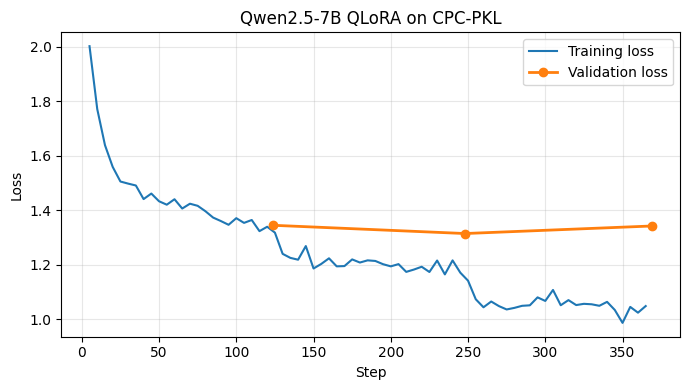

Validation loss per epoch: [1.3441, 1.3139, 1.3416]


In [8]:
# ===== CELL 8: Training / validation loss curve (paper figure) =====
import json, matplotlib.pyplot as plt
log = json.load(open(f"{MODEL_DIR}/log_history.json"))
tr = [(x["step"], x["loss"]) for x in log if "loss" in x]
ev = [(x["step"], x["eval_loss"]) for x in log if "eval_loss" in x]
plt.figure(figsize=(7, 4))
plt.plot(*zip(*tr), label="Training loss", linewidth=1.5)
plt.plot(*zip(*ev), "o-", label="Validation loss", linewidth=2)
plt.xlabel("Step"); plt.ylabel("Loss"); plt.title("Qwen2.5-7B QLoRA on CPC-PKL")
plt.grid(alpha=0.3); plt.legend(); plt.tight_layout()
plt.savefig(f"{EVAL_DIR}/loss_curve.png", dpi=200)
plt.show()
print("Validation loss per epoch:", [round(v, 4) for _, v in ev])

In [9]:
# ===== CELL 9: Bundle results for download =====
!cd /kaggle/working && zip -qr cpc_pkl_results.zip eval_clean preds data train_log.txt gen_base_log.txt gen_ft_log.txt \
    qwen25-7b-cpc-lora/final qwen25-7b-cpc-lora/log_history.json
!ls -lh /kaggle/working/cpc_pkl_results.zip
print("Download from the Output tab (right panel) or the notebook's Output section after the commit finishes.")

-rw-r--r-- 1 root root 149M Oct 20 20:34 /kaggle/working/cpc_pkl_results.zip
Download from the Output tab (right panel) or the notebook's Output section after the commit finishes.


In [10]:
# ===== CELL 10: RAG retrieval index (hybrid: dense BGE + BM25 + provision match) =====
# Knowledge base = train + val answers only (never the test answers -> no leakage)
import subprocess, sys, importlib.util
for pkg, pipname in [("rank_bm25", "rank_bm25"), ("sentence_transformers", "sentence-transformers==3.4.1")]:
    if importlib.util.find_spec(pkg) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--no-deps", pipname], check=True)

import json, os, re, numpy as np, torch
from rank_bm25 import BM25Okapi
from sentence_transformers import SentenceTransformer

WORK, DATA_DIR = "/kaggle/working", "/kaggle/working/data"
RAG_DIR = f"{WORK}/rag"; os.makedirs(RAG_DIR, exist_ok=True)
TOP_K = 3
load = lambda p: [json.loads(l) for l in open(p, encoding="utf-8")]

# provision extractor (same as Cell 7)
_ROM = {"I": 1, "V": 5, "X": 10, "L": 50, "C": 100}
def _roman(s):
    s = s.upper(); t = 0
    for i, c in enumerate(s):
        v = _ROM[c]; t += -v if i + 1 < len(s) and _ROM[s[i + 1]] > v else v
    return t
_NUM  = r"\d{1,3}(?!\d)[A-Za-z]?(?:\s*\([^)]{1,6}\))*"
_LIST = rf"{_NUM}(?:\s*(?:,|and|&|to|or|-)\s*{_NUM})*"
SEC_RE = re.compile(rf"\b(?:sections?|ss?\.)\s*({_LIST})", re.I)
ORD_RE = re.compile(rf"\b(?:order|o\.)\s*([IVXLC]+|\d{{1,2}}(?!\d))\b(?:\s*,?\s*(?:rules?|r\.)\s*({_LIST}))?", re.I)
_nums = lambda g: [n.upper() for n in re.findall(r"\d{1,3}[A-Za-z]?", re.sub(r"\([^)]*\)", "", g))]
def provisions(text):
    P = set()
    for m in SEC_RE.finditer(text):
        P |= {f"S{n}" for n in _nums(m.group(1))}
    for m in ORD_RE.finditer(text):
        g = m.group(1); o = int(g) if g.isdigit() else _roman(g)
        if 1 <= o <= 51:
            P |= {f"O{o}R{r}" for r in _nums(m.group(2))} if m.group(2) else {f"O{o}"}
    return P

kb   = load(f"{DATA_DIR}/train.jsonl") + load(f"{DATA_DIR}/val.jsonl")
test = load(f"{DATA_DIR}/test.jsonl")
kb_qprov = [provisions(d["question"]) for d in kb]
print(f"Knowledge base: {len(kb)} QA pairs (train+val) | test questions: {len(test)}")

# dense retrieval
emb = SentenceTransformer("BAAI/bge-base-en-v1.5", device="cuda:0")
emb.max_seq_length = 512
kb_vec = emb.encode([d["question"] + "\n" + d["answer"] for d in kb], batch_size=32,
                    normalize_embeddings=True, show_progress_bar=True)
q_vec  = emb.encode(["Represent this sentence for searching relevant passages: " + t["question"] for t in test],
                    batch_size=32, normalize_embeddings=True)
dense = q_vec @ kb_vec.T

# sparse retrieval
tokz = lambda s: re.findall(r"[a-z0-9]+", s.lower())
bm25 = BM25Okapi([tokz(d["question"] + " " + d["answer"]) for d in kb])

def rrf_rank(scores):  # rank position for reciprocal rank fusion
    r = np.empty_like(scores, dtype=float); r[np.argsort(-scores)] = np.arange(len(scores)); return r

retrieved = []
for i, t in enumerate(test):
    sparse = bm25.get_scores(tokz(t["question"]))
    fused = 1 / (60 + rrf_rank(dense[i])) + 1 / (60 + rrf_rank(sparse))
    qp = provisions(t["question"])
    if qp:  # boost KB entries whose question is about the same provision
        fused = fused + np.array([0.02 * len(qp & p) for p in kb_qprov])
    top = np.argsort(-fused)[:TOP_K]
    retrieved.append({"id": t["id"], "kb_index": top.tolist(),
                      "kb_ids": [kb[j]["id"] for j in top]})

with open(f"{RAG_DIR}/retrieved.jsonl", "w", encoding="utf-8") as f:
    for r in retrieved:
        f.write(json.dumps(r) + "\n")
json.dump(kb, open(f"{RAG_DIR}/kb.json", "w", encoding="utf-8"), ensure_ascii=False)

# retrieval quality: does any retrieved passage share a provision with the reference answer?
hit = [bool(provisions(t["answer"]) & set().union(*[provisions(kb[j]["answer"]) for j in r["kb_index"]]))
       for t, r in zip(test, retrieved) if provisions(t["answer"])]
print(f"Retrieval provision-hit@{TOP_K}: {np.mean(hit):.3f}  (over {len(hit)} questions whose reference names a provision)")
del emb; torch.cuda.empty_cache()
print("Saved:", os.listdir(RAG_DIR))

Knowledge base: 2221 QA pairs (train+val) | test questions: 246


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

...

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/70 [00:00<?, ?it/s]

Retrieval provision-hit@3: 0.897  (over 243 questions whose reference names a provision)
Saved: ['retrieved.jsonl', 'kb.json']


In [14]:
%%writefile /kaggle/working/generate_rag.py
# ===== CELL 11: RAG generation script (each GPU answers half; auto-splits batches on out-of-memory) =====
import os, sys, json, torch
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig
from peft import PeftModel

MODE     = sys.argv[1]                       # "base_rag" or "ft_rag"
MODEL_ID = "Qwen/Qwen2.5-7B-Instruct"
ADAPTER  = "/kaggle/working/qwen25-7b-cpc-lora/final"
TEST     = "/kaggle/working/data/test.jsonl"
RAG_DIR  = "/kaggle/working/rag"
PRED_DIR = "/kaggle/working/preds"
SYSTEM   = "You are an expert Pakistani legal assistant specialising in the Code of Civil Procedure (CPC) 1908."
BATCH, MAX_NEW, CTX_WORDS = 16, 1024, 350

rank  = int(os.environ.get("LOCAL_RANK", 0))
world = int(os.environ.get("WORLD_SIZE", 1))
torch.cuda.set_device(rank); torch.manual_seed(42)

kb  = json.load(open(f"{RAG_DIR}/kb.json", encoding="utf-8"))
ret = {r["id"]: r["kb_index"] for r in map(json.loads, open(f"{RAG_DIR}/retrieved.jsonl", encoding="utf-8"))}

def user_msg(q, qid):
    ctx = []
    for n, j in enumerate(ret[qid], 1):
        a = " ".join(kb[j]["answer"].split()[:CTX_WORDS])
        ctx.append(f"[{n}] Question: {kb[j]['question']}\nAnswer: {a}")
    return ("Use the reference material below to answer the question. Rely on it for section, order and "
            "rule numbers and for case law. Cite a case only if it appears in the reference material; "
            "if the material does not contain a relevant case, do not cite any case.\n\n"
            "### Reference material\n" + "\n\n".join(ctx) + f"\n\n### Question\n{q}")

rows = [json.loads(l) for l in open(TEST, encoding="utf-8")][rank::world]
out_path = f"{PRED_DIR}/{MODE}_rank{rank}.jsonl"
done = set()
if os.path.exists(out_path):
    done = {json.loads(l)["id"] for l in open(out_path, encoding="utf-8")}
rows = sorted([r for r in rows if r["id"] not in done], key=lambda r: len(r["question"]))
print(f"[{MODE} rank {rank}] {len(rows)} questions to answer ({len(done)} already done)", flush=True)

tok = AutoTokenizer.from_pretrained(MODEL_ID)
tok.padding_side = "left"
if tok.pad_token is None:
    tok.pad_token = tok.eos_token
bnb = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4",
                         bnb_4bit_use_double_quant=True, bnb_4bit_compute_dtype=torch.float16)
model = AutoModelForCausalLM.from_pretrained(MODEL_ID, quantization_config=bnb, torch_dtype=torch.float16,
                                             device_map={"": rank}, attn_implementation="sdpa")
if MODE == "ft_rag":
    model = PeftModel.from_pretrained(model, ADAPTER)
model.eval()

def prompt(r):
    return tok.apply_chat_template([{"role": "system", "content": SYSTEM},
                                    {"role": "user", "content": user_msg(r["question"], r["id"])}],
                                   tokenize=False, add_generation_prompt=True)

def generate(b):
    """Generate for batch b; on out-of-memory, split the batch in half and retry."""
    try:
        enc = tok([prompt(r) for r in b], return_tensors="pt", padding=True, add_special_tokens=False).to(rank)
        with torch.no_grad():
            gen = model.generate(**enc, max_new_tokens=MAX_NEW, do_sample=False,
                                 temperature=None, top_p=None, top_k=None,
                                 repetition_penalty=1.05, pad_token_id=tok.pad_token_id)
        new = gen[:, enc["input_ids"].shape[1]:]
        texts = tok.batch_decode(new, skip_special_tokens=True)
        n_tok = (new != tok.pad_token_id).sum(dim=1).tolist()
        del enc, gen, new
        return list(zip(b, texts, n_tok))
    except torch.OutOfMemoryError:
        torch.cuda.empty_cache()
        if len(b) == 1:
            raise
        print(f"[{MODE} rank {rank}] out of memory with batch {len(b)} -> splitting into {len(b)//2} + {len(b)-len(b)//2}", flush=True)
        h = len(b) // 2
        return generate(b[:h]) + generate(b[h:])

with open(out_path, "a", encoding="utf-8") as out:
    for i in range(0, len(rows), BATCH):
        for r, t, n in generate(rows[i:i + BATCH]):
            out.write(json.dumps({"id": r["id"], "prediction": t.strip(), "new_tokens": n,
                                  "truncated": n >= MAX_NEW}, ensure_ascii=False) + "\n")
        out.flush()
        torch.cuda.empty_cache()
        print(f"[{MODE} rank {rank}] {min(i + BATCH, len(rows))}/{len(rows)}", flush=True)
print(f"[{MODE} rank {rank}] DONE", flush=True)

Overwriting /kaggle/working/generate_rag.py


In [12]:
# ===== CELL 12: Generate RAG answers: base+RAG, then fine-tuned+RAG (both GPUs) =====
!cd /kaggle/working && TOKENIZERS_PARALLELISM=false torchrun --nproc_per_node=2 generate_rag.py base_rag 2>&1 | grep --line-buffered -v "Sliding Window" | tee gen_base_rag_log.txt
!cd /kaggle/working && TOKENIZERS_PARALLELISM=false torchrun --nproc_per_node=2 generate_rag.py ft_rag   2>&1 | grep --line-buffered -v "Sliding Window" | tee gen_ft_rag_log.txt

import glob
for m in ["base_rag", "ft_rag"]:
    n = sum(1 for f in glob.glob(f"/kaggle/working/preds/{m}_rank*.jsonl") for _ in open(f))
    print(f"{m}: {n} predictions")

huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)


W1020 20:40:27.832000 738 torch/distributed/run.py:851] 
W1020 20:40:27.832000 738 torch/distributed/run.py:851] *****************************************
W1020 20:40:27.832000 738 torch/distributed/run.py:851] Setting OMP_NUM_THREADS environment variable for each process to be 1 in default, to avoid your system being overloaded, please further tune the variable for optimal performance in your application as needed. 
W1020 20:40:27.832000 738 torch/distributed/run.py:851] *****************************************
[base_rag rank 1] 123 questions to answer (0 already done)
[base_rag rank 0] 123 questions to answer (0 already done)
Loading checkpoint shards: 100%|██████████| 4/4 [00:18<00:00,  4.69s/it]
[base_rag rank 0] 16/123
[base_rag rank 1] 16/123
[base_rag rank 0] 32/123
[base_rag rank 1] 32/123
[base_rag rank 0] 48/123
[base_rag rank 1] 48/123
[base_rag rank 0] 64/123
[base_rag rank 1] 64/123
[base_rag rank 0] 80/123
[base_rag rank 1] 80/123
[base_rag rank 0] 96/123
[base_rag rank 

huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)


W1020 21:29:38.840000 781 torch/distributed/run.py:851] 
W1020 21:29:38.840000 781 torch/distributed/run.py:851] *****************************************
W1020 21:29:38.840000 781 torch/distributed/run.py:851] Setting OMP_NUM_THREADS environment variable for each process to be 1 in default, to avoid your system being overloaded, please further tune the variable for optimal performance in your application as needed. 
W1020 21:29:38.840000 781 torch/distributed/run.py:851] *****************************************
[ft_rag rank 1] 123 questions to answer (0 already done)[ft_rag rank 0] 123 questions to answer (0 already done)

Loading checkpoint shards: 100%|██████████| 4/4 [00:18<00:00,  4.57s/it]
Traceback (most recent call last):
  File "/kaggle/working/generate_rag.py", line 62, in <module>
    gen = model.generate(**enc, max_new_tokens=MAX_NEW, do_sample=False,
                         temperature=None, top_p=None, top_k=None,
                         repetition_penalty=1.05, pad_to

In [15]:
# ===== CELL 12b: Fine-tuned+RAG only (base+RAG already finished) =====
!cd /kaggle/working && TOKENIZERS_PARALLELISM=false PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True \
  torchrun --nproc_per_node=2 generate_rag.py ft_rag 2>&1 | grep --line-buffered -v "Sliding Window" | tee gen_ft_rag_log.txt

import glob
for m in ["base_rag", "ft_rag"]:
    n = sum(1 for f in glob.glob(f"/kaggle/working/preds/{m}_rank*.jsonl") for _ in open(f))
    print(f"{m}: {n} predictions")

huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)


W1020 21:42:27.029000 811 torch/distributed/run.py:851] 
W1020 21:42:27.029000 811 torch/distributed/run.py:851] *****************************************
W1020 21:42:27.029000 811 torch/distributed/run.py:851] Setting OMP_NUM_THREADS environment variable for each process to be 1 in default, to avoid your system being overloaded, please further tune the variable for optimal performance in your application as needed. 
W1020 21:42:27.029000 811 torch/distributed/run.py:851] *****************************************
[ft_rag rank 1] 123 questions to answer (0 already done)
[ft_rag rank 0] 123 questions to answer (0 already done)
Loading checkpoint shards: 100%|██████████| 4/4 [00:19<00:00,  4.76s/it]
[ft_rag rank 0] out of memory with batch 16 -> splitting into 8 + 8
[ft_rag rank 1] 16/123
[ft_rag rank 1] out of memory with batch 16 -> splitting into 8 + 8
[ft_rag rank 0] 16/123
[ft_rag rank 0] out of memory with batch 16 -> splitting into 8 + 8
[ft_rag rank 1] 32/123
[ft_rag rank 1] out o

In [16]:
# ===== CELL 13: Final evaluation of all 4 systems (base, fine-tuned, base+RAG, fine-tuned+RAG) =====
import json, glob, re, os, numpy as np, pandas as pd
from scipy.stats import wilcoxon
from rouge_score import rouge_scorer
from bert_score import score as bertscore

WORK = "/kaggle/working"; DATA_DIR, PRED_DIR, RAG_DIR = f"{WORK}/data", f"{WORK}/preds", f"{WORK}/rag"
OUT = f"{WORK}/eval_final"; os.makedirs(OUT, exist_ok=True)
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 50); pd.set_option("display.max_rows", 200)
load = lambda p: [json.loads(l) for l in open(p, encoding="utf-8")]
SYSTEMS = {"base": "Base", "ft": "Fine-tuned", "base_rag": "Base+RAG", "ft_rag": "Fine-tuned+RAG"}
CATS = ["DEFINITIONAL", "PROCEDURAL", "SCENARIO", "COMPARATIVE", "CONSEQUENCE"]

# ---------- extractors (same as Cell 7) ----------
_ROM = {"I": 1, "V": 5, "X": 10, "L": 50, "C": 100}
def _roman(s):
    s = s.upper(); t = 0
    for i, c in enumerate(s):
        v = _ROM[c]; t += -v if i + 1 < len(s) and _ROM[s[i + 1]] > v else v
    return t
_NUM  = r"\d{1,3}(?!\d)[A-Za-z]?(?:\s*\([^)]{1,6}\))*"
_LIST = rf"{_NUM}(?:\s*(?:,|and|&|to|or|-)\s*{_NUM})*"
SEC_RE = re.compile(rf"\b(?:sections?|ss?\.)\s*({_LIST})", re.I)
ORD_RE = re.compile(rf"\b(?:order|o\.)\s*([IVXLC]+|\d{{1,2}}(?!\d))\b(?:\s*,?\s*(?:rules?|r\.)\s*({_LIST}))?", re.I)
_nums = lambda g: [n.upper() for n in re.findall(r"\d{1,3}[A-Za-z]?", re.sub(r"\([^)]*\)", "", g))]
def provisions(text):
    P = set()
    for m in SEC_RE.finditer(text):
        P |= {f"S{n}" for n in _nums(m.group(1))}
    for m in ORD_RE.finditer(text):
        g = m.group(1); o = int(g) if g.isdigit() else _roman(g)
        if 1 <= o <= 51:
            P |= {f"O{o}R{r}" for r in _nums(m.group(2))} if m.group(2) else {f"O{o}"}
    return P
_REP = r"SCMR|CLC|MLD|YLR|PLJ|CLD|PCr\.?\s?LJ|PTD|NLR|KLR|MLR|CLJ|SCJ|PLC|GBLR"
_CRT = r"SC|FSC|Lah|Lahore|Kar|Karachi|Pesh|Peshawar|Quetta|Isl|Islamabad|AJK|Bal|L|K|P|Q|B"
CASE_A = re.compile(rf"\b((?:19|20)\d{{2}})\s+({_REP})\s+(\d{{1,4}})\b")
CASE_B = re.compile(rf"\b(?:PLD|P\.L\.D\.?|P)\s+((?:19|20)\d{{2}})\s+(?:{_CRT})\.?\s+(\d{{1,4}})\b")
CASE_C = re.compile(r"\b((?:19|20)\d{2})\s+(?:SC|FSC|Lah|Kar|Pesh|Quetta|L|K|Q)\s+(\d{1,4})\b")
def cases(text):
    C = {f"{y}-{re.sub(r'[^A-Z]', '', rep.upper())}-{p}" for y, rep, p in CASE_A.findall(text)}
    C |= {f"{y}-PLD-{p}" for y, p in CASE_B.findall(text)} | {f"{y}-PLD-{p}" for y, p in CASE_C.findall(text)}
    return C

# ---------- load ----------
df = pd.DataFrame(load(f"{DATA_DIR}/test.jsonl"))
for m in SYSTEMS:
    preds = {r["id"]: r for f in sorted(glob.glob(f"{PRED_DIR}/{m}_rank*.jsonl")) for r in load(f)}
    assert len(preds) == len(df), f"{m}: {len(preds)} predictions, expected {len(df)}"
    df[f"{m}_answer"] = df["id"].map(lambda i: preds[i]["prediction"])
    df[f"{m}_truncated"] = df["id"].map(lambda i: preds[i]["truncated"])

known = set()
for s in ["train", "val"]:
    for r in load(f"{DATA_DIR}/{s}.jsonl"):
        known |= cases(r["answer"])
kb = json.load(open(f"{RAG_DIR}/kb.json", encoding="utf-8"))
ret = {r["id"]: r["kb_index"] for r in load(f"{RAG_DIR}/retrieved.jsonl")}
df["ctx_cases"] = df["id"].map(lambda i: set().union(*[cases(kb[j]["answer"]) for j in ret[i]]))
df["q_prov"], df["ref_prov"], df["ref_cases"] = df["question"].map(provisions), df["answer"].map(provisions), df["answer"].map(cases)
df["ref_prov_novel"] = [len(r - q) for r, q in zip(df["ref_prov"], df["q_prov"])]
print(f"Test: {len(df)} | known train+val cases: {len(known)} | "
      f"reference cases also present in retrieved context: {sum(len(r & c) for r, c in zip(df['ref_cases'], df['ctx_cases']))}"
      f"/{df['ref_cases'].map(len).sum()}")

# ---------- per-example metrics ----------
scorer = rouge_scorer.RougeScorer(["rouge1", "rouge2", "rougeL"], use_stemmer=True)
for m in SYSTEMS:
    rs = [scorer.score(a, h) for a, h in zip(df["answer"], df[f"{m}_answer"])]
    for k in ["rouge1", "rouge2", "rougeL"]:
        df[f"{m}_{k}"] = [r[k].fmeasure for r in rs]
    _, _, F = bertscore(df[f"{m}_answer"].tolist(), df["answer"].tolist(), lang="en",
                        batch_size=16, device="cuda:0", verbose=False)
    df[f"{m}_bertF1"] = F.numpy()
    df[f"{m}_words"] = df[f"{m}_answer"].str.split().str.len()
    P = df[f"{m}_answer"].map(provisions)
    df[f"{m}_prov_pred"] = P.map(len)
    df[f"{m}_prov_tp"] = [len(p & r) for p, r in zip(P, df["ref_prov"])]
    df[f"{m}_prov_tp_novel"] = [len((p & r) - q) for p, r, q in zip(P, df["ref_prov"], df["q_prov"])]
    C = df[f"{m}_answer"].map(cases)
    rag = m.endswith("_rag")
    df[f"{m}_cases"] = C.map(len)
    df[f"{m}_c_ref"] = [len(c & r) for c, r in zip(C, df["ref_cases"])]
    # grounded = in retrieved context (only meaningful for RAG systems)
    df[f"{m}_c_ctx"] = [len((c - r) & x) if rag else 0 for c, r, x in zip(C, df["ref_cases"], df["ctx_cases"])]
    df[f"{m}_c_mem"] = [len((c - r - (x if rag else set())) & known) for c, r, x in zip(C, df["ref_cases"], df["ctx_cases"])]
    df[f"{m}_c_unv"] = [len(c - r - known - (x if rag else set())) for c, r, x in zip(C, df["ref_cases"], df["ctx_cases"])]
    df[f"{m}_case_list"] = C.map(lambda s: "; ".join(sorted(s)))

sd = lambda a, b: a / b if b else float("nan")
def summarise(d):
    out = {}
    for m, name in SYSTEMS.items():
        nc = d[f"{m}_cases"].sum()
        out[name] = {
            "ROUGE-1": d[f"{m}_rouge1"].mean(), "ROUGE-2": d[f"{m}_rouge2"].mean(),
            "ROUGE-L": d[f"{m}_rougeL"].mean(), "BERTScore-F1": d[f"{m}_bertF1"].mean(),
            "Provision recall": sd(d[f"{m}_prov_tp"].sum(), d["ref_prov"].map(len).sum()),
            "Provision precision": sd(d[f"{m}_prov_tp"].sum(), d[f"{m}_prov_pred"].sum()),
            "Recall of provisions not named in Q": sd(d[f"{m}_prov_tp_novel"].sum(), d["ref_prov_novel"].sum()),
            "Case citations made": int(nc),
            "  matching reference": int(d[f"{m}_c_ref"].sum()),
            "  from retrieved context": int(d[f"{m}_c_ctx"].sum()),
            "  from training memory (wrong question)": int(d[f"{m}_c_mem"].sum()),
            "  unverifiable (not in any data)": int(d[f"{m}_c_unv"].sum()),
            "Citation accuracy (match ref)": sd(d[f"{m}_c_ref"].sum(), nc),
            "Grounded rate (ref or context)": sd(d[f"{m}_c_ref"].sum() + d[f"{m}_c_ctx"].sum(), nc),
            "Unverifiable-case rate": sd(d[f"{m}_c_unv"].sum(), nc),
            "Answers citing >=1 case": int((d[f"{m}_cases"] > 0).sum()),
            "Avg answer length (words)": d[f"{m}_words"].mean(),
            "Truncated answers": int(d[f"{m}_truncated"].sum()),
        }
    return pd.DataFrame(out)

overall = summarise(df)
print("\n===== FINAL RESULTS: 4 SYSTEMS (n = 246) =====")
print(overall.to_string(float_format=lambda x: f"{x:.4f}"))

print("\n===== SIGNIFICANCE (paired Wilcoxon) =====")
sig = []
for a, b in [("ft", "base"), ("base_rag", "base"), ("ft_rag", "ft"), ("ft_rag", "base_rag"), ("ft_rag", "base")]:
    for k in ["rougeL", "bertF1"]:
        p = wilcoxon(df[f"{a}_{k}"], df[f"{b}_{k}"]).pvalue
        sig.append({"comparison": f"{SYSTEMS[a]} vs {SYSTEMS[b]}", "metric": k,
                    "mean_a": df[f"{a}_{k}"].mean(), "mean_b": df[f"{b}_{k}"].mean(), "p": p})
sig = pd.DataFrame(sig); print(sig.to_string(index=False, float_format=lambda x: f"{x:.4g}"))

print("\n===== PER CATEGORY =====")
rows = []
for cat in CATS:
    s = summarise(df[df["category"] == cat])
    r = {"category": cat, "n": int((df["category"] == cat).sum())}
    for name in SYSTEMS.values():
        for k in ["ROUGE-L", "BERTScore-F1", "Provision recall", "Unverifiable-case rate"]:
            r[f"{name} | {k}"] = s.loc[k, name]
    rows.append(r)
per_cat = pd.DataFrame(rows).set_index("category")
print(per_cat.T.to_string(float_format=lambda x: f"{x:.4f}"))

overall.to_csv(f"{OUT}/summary_overall_4systems.csv"); sig.to_csv(f"{OUT}/significance.csv", index=False)
per_cat.to_csv(f"{OUT}/summary_per_category.csv")
o = df.copy()
for c in ["q_prov", "ref_prov", "ref_cases", "ctx_cases"]:
    o[c] = o[c].map(lambda s: "; ".join(sorted(s)))
o.to_csv(f"{OUT}/per_example_4systems.csv", index=False)
with open(f"{OUT}/examples_4systems.md", "w", encoding="utf-8") as f:
    for cat in CATS:
        r = df[df["category"] == cat].sort_values("ft_rag_rougeL").iloc[len(df[df["category"] == cat]) // 2]
        f.write(f"## {cat} (id {r['id']})\n\n**Question:** {r['question']}\n\n### Reference\n{r['answer']}\n\n")
        for m, name in SYSTEMS.items():
            f.write(f"### {name} (ROUGE-L {r[f'{m}_rougeL']:.3f}; cases: {r[f'{m}_case_list'] or 'none'})\n{r[f'{m}_answer']}\n\n")
        f.write("---\n\n")
print("\nSaved to", OUT, ":", sorted(os.listdir(OUT)))

Test: 246 | known train+val cases: 2502 | reference cases also present in retrieved context: 144/562


Some weights of RobertaModel were not initialized from the model checkpoint at roberta-large and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
Some weights of RobertaModel were not initialized from the model checkpoint at roberta-large and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
Some weights of RobertaModel were not initialized from the model checkpoint at roberta-large and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
Some weights of RobertaModel were not initialized from the model checkpoint at roberta-large and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You sho


===== FINAL RESULTS: 4 SYSTEMS (n = 246) =====
                                            Base  Fine-tuned  Base+RAG  Fine-tuned+RAG
ROUGE-1                                   0.4770      0.5360    0.5158          0.5497
ROUGE-2                                   0.1662      0.2134    0.2156          0.2385
ROUGE-L                                   0.2339      0.2660    0.2653          0.2779
BERTScore-F1                              0.8410      0.8621    0.8571          0.8640
Provision recall                          0.3622      0.3798    0.4744          0.4952
Provision precision                       0.5855      0.5603    0.6592          0.5733
Recall of provisions not named in Q       0.0301      0.0877    0.1855          0.2381
Case citations made                       1.0000    366.0000  163.0000        499.0000
  matching reference                      1.0000      5.0000   52.0000         68.0000
  from retrieved context                  0.0000      0.0000  110.0000        256.

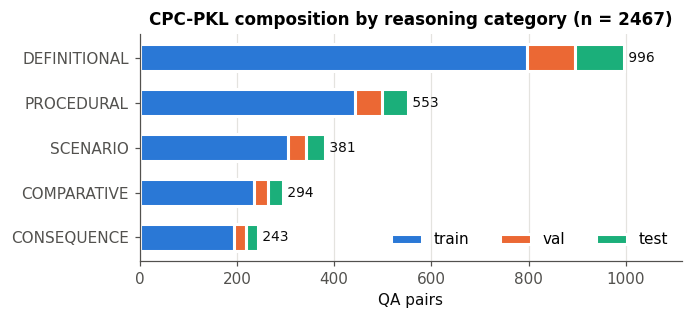

saved fig1_dataset_composition


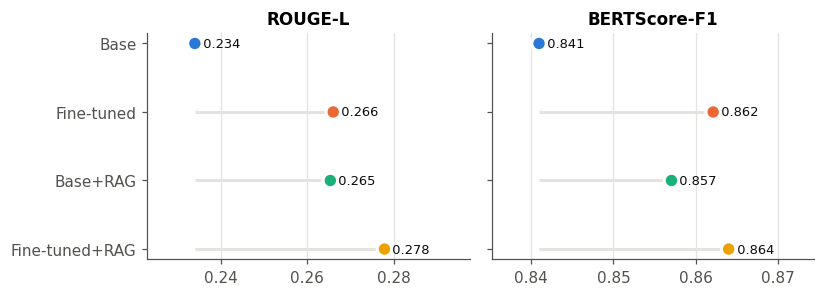

saved fig2_answer_quality


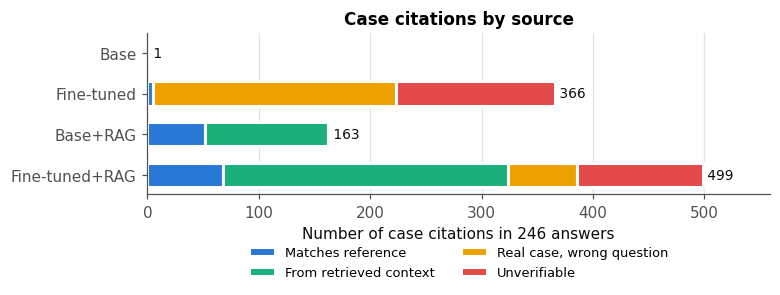

saved fig3_citation_sources


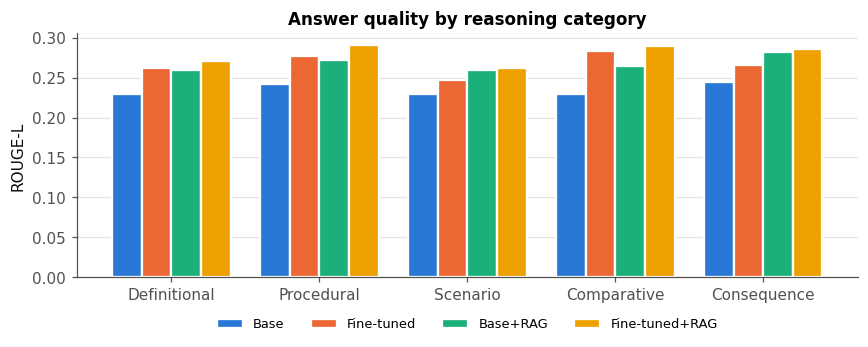

saved fig4_rougeL_by_category


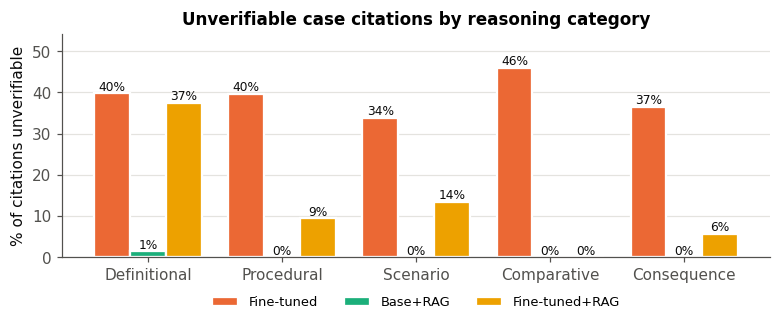

saved fig5_unverifiable_by_category


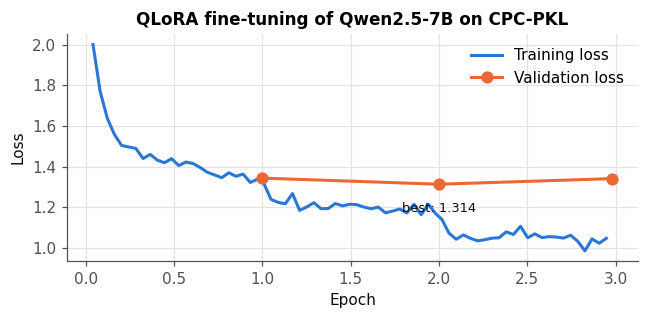

saved fig6_loss_curve

All figures in /kaggle/working/figures : ['fig1_dataset_composition.pdf', 'fig1_dataset_composition.png', 'fig2_answer_quality.pdf', 'fig2_answer_quality.png', 'fig3_citation_sources.pdf', 'fig3_citation_sources.png', 'fig4_rougeL_by_category.pdf', 'fig4_rougeL_by_category.png', 'fig5_unverifiable_by_category.pdf', 'fig5_unverifiable_by_category.png', 'fig6_loss_curve.pdf', 'fig6_loss_curve.png']


In [17]:
# ===== CELL 15: Paper figures (PNG 300 dpi + PDF for LaTeX) =====
import json, os, numpy as np, pandas as pd, matplotlib.pyplot as plt

W = "/kaggle/working"
OUT = f"{W}/eval_final"; FIG = f"{W}/figures"; os.makedirs(FIG, exist_ok=True)
df  = pd.read_csv(f"{OUT}/per_example_4systems.csv")
ov  = pd.read_csv(f"{OUT}/summary_overall_4systems.csv", index_col=0).apply(pd.to_numeric, errors="coerce")
SYS   = {"base": "Base", "ft": "Fine-tuned", "base_rag": "Base+RAG", "ft_rag": "Fine-tuned+RAG"}
COLOR = {"base": "#2a78d6", "ft": "#eb6834", "base_rag": "#1baf7a", "ft_rag": "#eda100"}  # fixed order, validated
CATS  = ["DEFINITIONAL", "PROCEDURAL", "SCENARIO", "COMPARATIVE", "CONSEQUENCE"]
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"

plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.edgecolor": INK2, "axes.labelcolor": INK, "xtick.color": INK2, "ytick.color": INK2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "axes.axisbelow": True,
    "grid.color": GRID, "grid.linewidth": 0.8, "legend.frameon": False, "figure.dpi": 110,
})
def save(fig, name):
    fig.tight_layout()
    for ext in ("png", "pdf"):
        fig.savefig(f"{FIG}/{name}.{ext}", dpi=300, bbox_inches="tight")
    plt.show(); print("saved", name)
def label_bars(ax, bars, fmt, horizontal=False):
    for b in bars:
        v = b.get_width() if horizontal else b.get_height()
        if horizontal:
            ax.text(v, b.get_y() + b.get_height() / 2, " " + fmt.format(v), va="center", ha="left", fontsize=8.5, color=INK)
        else:
            ax.text(b.get_x() + b.get_width() / 2, v, fmt.format(v), va="bottom", ha="center", fontsize=8, color=INK)

# ---- Figure 1: dataset composition (full dataset, train/val/test stacked) ----
splits = {s: pd.read_json(f"{W}/data/{s}.jsonl", lines=True)["category"].value_counts() for s in ["train", "val", "test"]}
fig, ax = plt.subplots(figsize=(6.4, 3.0))
left = np.zeros(len(CATS))
for s, c in zip(["train", "val", "test"], ["#2a78d6", "#eb6834", "#1baf7a"]):
    v = np.array([splits[s].get(k, 0) for k in CATS])
    ax.barh(CATS[::-1], v[::-1], left=left[::-1], color=c, label=s, height=0.6, edgecolor="white", linewidth=2)
    left += v
for i, tot in enumerate(left[::-1]):
    ax.text(tot, i, f" {int(tot)}", va="center", fontsize=9, color=INK)
ax.set_xlabel("QA pairs"); ax.set_title(f"CPC-PKL composition by reasoning category (n = {int(left.sum())})")
ax.grid(axis="y", visible=False); ax.legend(ncol=3, loc="lower right"); ax.set_xlim(0, left.max() * 1.12)
save(fig, "fig1_dataset_composition")

# ---- Figure 2: answer quality, two panels (different scales -> never a dual axis) ----
fig, axes = plt.subplots(1, 2, figsize=(7.6, 2.8), sharey=True)
names = list(SYS.values())[::-1]
for ax, metric in [(axes[0], "ROUGE-L"), (axes[1], "BERTScore-F1")]:
    vals = [ov.loc[metric, n] for n in names]
    cols = [COLOR[m] for m in list(SYS)[::-1]]
    ax.hlines(names, min(vals), vals, color=GRID, linewidth=2, zorder=1)          # dot plot: no zero baseline needed
    ax.scatter(vals, names, s=90, color=cols, edgecolor="white", linewidth=2, zorder=3)
    for v, n in zip(vals, names):
        ax.text(v, n, f"  {v:.3f}", va="center", ha="left", fontsize=8.5, color=INK)
    span = max(vals) - min(vals) or 0.01
    ax.set_xlim(min(vals) - span * 0.25, max(vals) + span * 0.45)
    ax.set_title(metric); ax.grid(axis="y", visible=False)
save(fig, "fig2_answer_quality")

# ---- Figure 3: where do the case citations come from? (the key figure) ----
parts = [("  matching reference", "Matches reference", "#2a78d6"),
         ("  from retrieved context", "From retrieved context", "#1baf7a"),
         ("  from training memory (wrong question)", "Real case, wrong question", "#eda100"),
         ("  unverifiable (not in any data)", "Unverifiable", "#e34948")]
fig, ax = plt.subplots(figsize=(7.2, 3.0))
names = list(SYS.values())[::-1]
left = np.zeros(len(names))
for key, lab, c in parts:
    v = np.array([ov.loc[key, n] for n in names], dtype=float)
    ax.barh(names, v, left=left, color=c, label=lab, height=0.6, edgecolor="white", linewidth=2)
    left += v
for i, tot in enumerate(left):
    ax.text(tot, i, f" {int(tot)}", va="center", fontsize=9, color=INK)
ax.set_xlabel("Number of case citations in 246 answers")
ax.set_title("Case citations by source")
ax.grid(axis="y", visible=False); ax.set_xlim(0, max(left.max(), 1) * 1.12)
ax.legend(ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.25), fontsize=8.5)
save(fig, "fig3_citation_sources")

# ---- Figure 4: ROUGE-L per reasoning category, 4 systems ----
fig, ax = plt.subplots(figsize=(8.0, 3.3))
x = np.arange(len(CATS)); w = 0.2
for k, m in enumerate(SYS):
    v = [df[df["category"] == c][f"{m}_rougeL"].mean() for c in CATS]
    ax.bar(x + (k - 1.5) * w, v, w, color=COLOR[m], label=SYS[m], edgecolor="white", linewidth=1.5)
ax.set_xticks(x); ax.set_xticklabels([c.title() for c in CATS])
ax.set_ylabel("ROUGE-L"); ax.set_title("Answer quality by reasoning category")
ax.grid(axis="x", visible=False); ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.12), fontsize=8.5)
save(fig, "fig4_rougeL_by_category")

# ---- Figure 5: unverifiable-citation rate by category (systems that cite cases) ----
fig, ax = plt.subplots(figsize=(7.2, 3.1))
cited = [m for m in SYS if df[f"{m}_cases"].sum() >= 20]
w = 0.8 / max(len(cited), 1)
for k, m in enumerate(cited):
    v = []
    for c in CATS:
        d = df[df["category"] == c]
        v.append(d[f"{m}_c_unv"].sum() / d[f"{m}_cases"].sum() * 100 if d[f"{m}_cases"].sum() else np.nan)
    bars = ax.bar(x + (k - (len(cited) - 1) / 2) * w, v, w, color=COLOR[m], label=SYS[m], edgecolor="white", linewidth=1.5)
    label_bars(ax, bars, "{:.0f}%")
ax.set_xticks(x); ax.set_xticklabels([c.title() for c in CATS])
ax.set_ylabel("% of citations unverifiable"); ax.set_title("Unverifiable case citations by reasoning category")
ax.grid(axis="x", visible=False); ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=len(cited), fontsize=8.5)
ax.set_ylim(0, np.nanmax([p.get_height() for p in ax.patches] + [1]) * 1.18)
save(fig, "fig5_unverifiable_by_category")

# ---- Figure 6: training / validation loss (restyled) ----
log = json.load(open(f"{W}/qwen25-7b-cpc-lora/log_history.json"))
tr = [(x_["epoch"], x_["loss"]) for x_ in log if "loss" in x_]
ev = [(x_["epoch"], x_["eval_loss"]) for x_ in log if "eval_loss" in x_]
fig, ax = plt.subplots(figsize=(6.0, 3.0))
ax.plot(*zip(*tr), color="#2a78d6", linewidth=2, label="Training loss")
ax.plot(*zip(*ev), color="#eb6834", linewidth=2, marker="o", markersize=7, label="Validation loss")
best = min(ev, key=lambda t: t[1])
ax.annotate(f"best: {best[1]:.3f}", best, textcoords="offset points", xytext=(0, -18), ha="center", fontsize=8.5, color=INK)
ax.set_xlabel("Epoch"); ax.set_ylabel("Loss"); ax.set_title("QLoRA fine-tuning of Qwen2.5-7B on CPC-PKL")
ax.legend()
save(fig, "fig6_loss_curve")

print("\nAll figures in", FIG, ":", sorted(os.listdir(FIG)))

In [18]:
# ===== CELL 15: Final packaging (fine-tuned adapter for Hugging Face + full results + figures) =====
import os

W = "/kaggle/working"
os.chdir(W)
assert os.path.isdir(f"{W}/figures"), "Run the figures cell (Cell 14) first"

# 1) Fine-tuned model (LoRA adapter only: what you upload to Hugging Face)
!zip -qr cpc_pkl_adapter.zip qwen25-7b-cpc-lora/final

# 2) Everything for the paper and GitHub: code, data splits, predictions, RAG, results, figures, logs
!zip -qr cpc_pkl_full_results.zip \
    train.py generate.py generate_rag.py \
    data preds rag eval_clean eval_final figures \
    qwen25-7b-cpc-lora/final qwen25-7b-cpc-lora/log_history.json \
    train_log.txt gen_base_log.txt gen_ft_log.txt gen_base_rag_log.txt gen_ft_rag_log.txt

!ls -lh cpc_pkl_adapter.zip cpc_pkl_full_results.zip
print("\nAdapter contents:", os.listdir(f"{W}/qwen25-7b-cpc-lora/final"))
print("Figures:", sorted(os.listdir(f"{W}/figures")))

huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)
huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)


-rw-r--r-- 1 root root 147M Oct 20 22:58 cpc_pkl_adapter.zip
-rw-r--r-- 1 root root 153M Oct 20 22:58 cpc_pkl_full_results.zip

Adapter contents: ['added_tokens.json', 'vocab.json', 'merges.txt', 'special_tokens_map.json', 'README.md', 'tokenizer_config.json', 'tokenizer.json', 'training_args.bin', 'adapter_model.safetensors', 'adapter_config.json']
Figures: ['fig1_dataset_composition.pdf', 'fig1_dataset_composition.png', 'fig2_answer_quality.pdf', 'fig2_answer_quality.png', 'fig3_citation_sources.pdf', 'fig3_citation_sources.png', 'fig4_rougeL_by_category.pdf', 'fig4_rougeL_by_category.png', 'fig5_unverifiable_by_category.pdf', 'fig5_unverifiable_by_category.png', 'fig6_loss_curve.pdf', 'fig6_loss_curve.png']


huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)
